In [1]:

# Task A1: Breast Cancer Diagnosis

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()

# Separate features and target
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Display dataset information
print("Dataset Shape:", X.shape)
print("\nFeature Names:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(data.target_names)

print("\nClass Distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))


Dataset Shape: (569, 30)

Feature Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target Classes:
['malignant' 'benign']

Class Distribution:
Benign       357
Malignant    212
Name: count, dtype: int64


In [2]:

# Summary statistics for all 30 features
summary_stats = X.describe().T

summary_stats = summary_stats.round(3)

display(summary_stats)


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


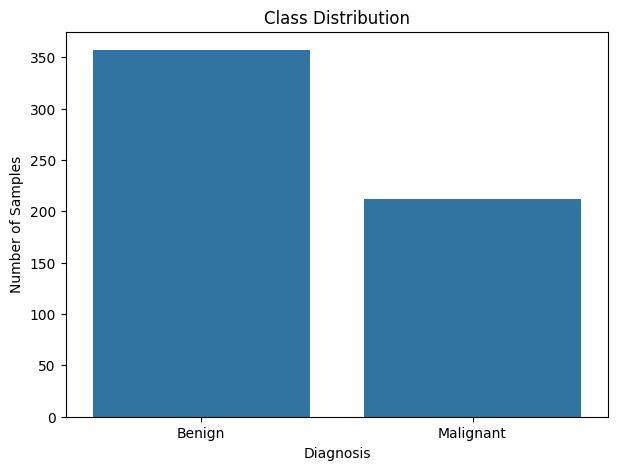

In [3]:

# Plot class distribution
class_counts = y.map({
    0: "Malignant",
    1: "Benign"
}).value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.show()


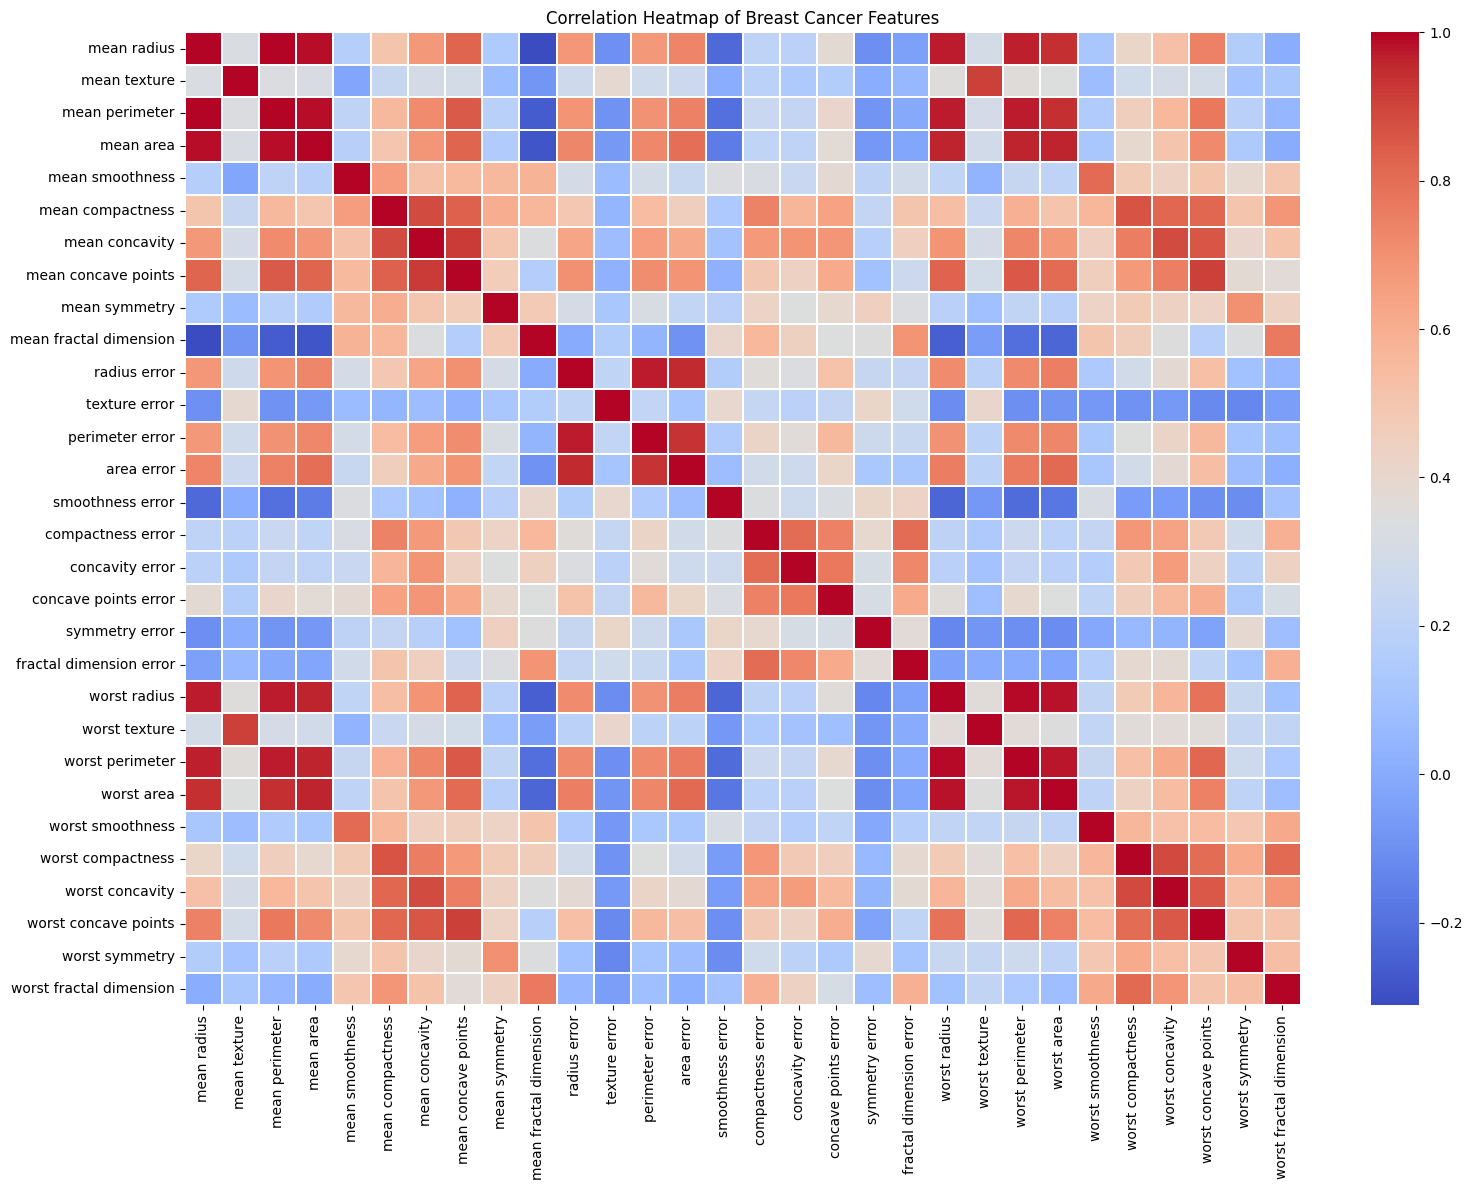

In [4]:
# Calculate correlation between features
correlation_matrix = X.corr()

# Plot correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Breast Cancer Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

In [5]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split information
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())



Training Samples: 455
Testing Samples: 114

Training Class Distribution:
1    285
0    170
Name: count, dtype: int64

Testing Class Distribution:
1    72
0    42
Name: count, dtype: int64


In [6]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000, random_state=42))
])

print("Logistic Regression Pipeline:")
print(lr_pipeline)


Logistic Regression Pipeline:
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=5000, random_state=42))])


In [7]:

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000, random_state=42))
])

# Model 2: Support Vector Machine (RBF)
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf', probability=True, random_state=42))
])

# Model 3: Random Forest
rf_pipeline = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

# Store all models
models = {
    'Logistic Regression': lr_pipeline,
    'SVM (RBF)': svm_pipeline,
    'Random Forest': rf_pipeline
}

print("Models created successfully!")

for name, model in models.items():
    print("\n", name)
    print(model)


Models created successfully!

 Logistic Regression
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=5000, random_state=42))])

 SVM (RBF)
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', SVC(probability=True, random_state=42))])

 Random Forest
Pipeline(steps=[('model', RandomForestClassifier(random_state=42))])


In [8]:

# Train all three models

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


Logistic Regression trained successfully!
SVM (RBF) trained successfully!
Random Forest trained successfully!


In [9]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 5-fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression parameter tuning
lr_params = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Logistic Regression Best Parameters:")
print(lr_grid.best_params_)

print("Best CV F1 Score:", lr_grid.best_score_)


# SVM parameter tuning
svm_params = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.01, 0.1, 1]
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("\nSVM Best Parameters:")
print(svm_grid.best_params_)

print("Best CV F1 Score:", svm_grid.best_score_)



Logistic Regression Best Parameters:
{'model__C': 0.1}
Best CV F1 Score: 0.9861164154764722

SVM Best Parameters:
{'model__C': 10, 'model__gamma': 0.01}
Best CV F1 Score: 0.9809869017218904


In [10]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Select tuned models and Random Forest
final_models = {
    'Logistic Regression': lr_grid.best_estimator_,
    'SVM (RBF)': svm_grid.best_estimator_,
    'Random Forest': rf_pipeline
}

results = []

for name, model in final_models.items():

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (Malignant)': precision_score(
            y_test, y_pred, pos_label=0
        ),
        'Recall (Malignant)': recall_score(
            y_test, y_pred, pos_label=0
        ),
        'F1 (Malignant)': f1_score(
            y_test, y_pred, pos_label=0
        ),
        'ROC-AUC': roc_auc_score(y_test, 1 - y_prob)
    })

# Display results
results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision (Malignant),Recall (Malignant),F1 (Malignant),ROC-AUC
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.0043
1,SVM (RBF),0.9825,0.9762,0.9762,0.9762,0.0023
2,Random Forest,0.9561,0.9512,0.9286,0.9398,0.0063


In [11]:

from sklearn.metrics import roc_auc_score

# Recalculate ROC-AUC for malignant class
for name, model in final_models.items():

    y_prob = model.predict_proba(X_test)[:, 0]

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        y_prob
    )

    print(name, "Malignant ROC-AUC:", round(auc, 4))


Logistic Regression Malignant ROC-AUC: 0.9957
SVM (RBF) Malignant ROC-AUC: 0.9977
Random Forest Malignant ROC-AUC: 0.9937


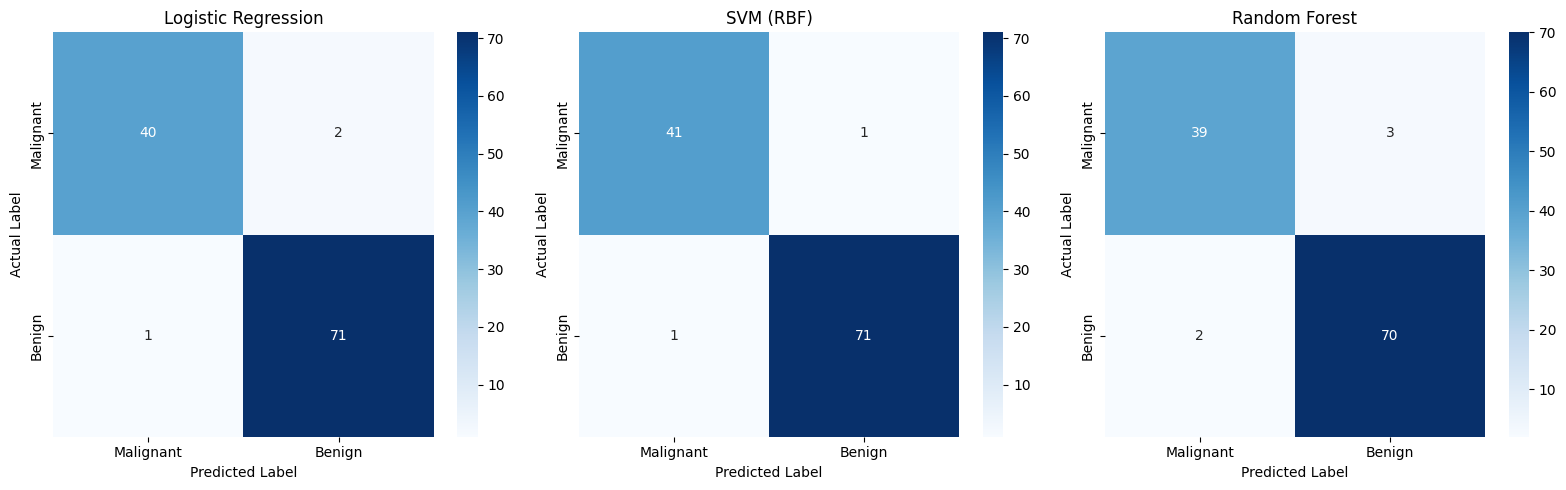

In [12]:

from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrices for all models
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, final_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Malignant', 'Benign'],
        yticklabels=['Malignant', 'Benign'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()


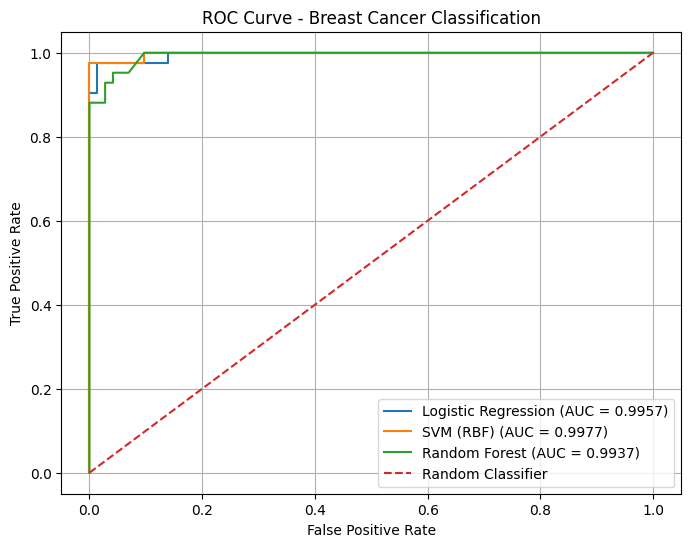

In [13]:

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, model in final_models.items():

    # Malignant probability
    y_prob = model.predict_proba(X_test)[:, 0]

    # Malignant as positive class
    y_true = (y_test == 0).astype(int)

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.4f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Breast Cancer Classification')

plt.legend()
plt.grid()
plt.savefig("roc_curve.png", dpi=300, bbox_inches='tight')
plt.show()


In [14]:

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# Get malignant probabilities from tuned SVM
best_model = svm_grid.best_estimator_

malignant_prob = best_model.predict_proba(X_test)[:, 0]

# Actual malignant labels
y_true = (y_test == 0).astype(int)

# Test different thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        malignant_prob >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(y_true, y_pred_threshold, zero_division=0),
        'Recall': recall_score(y_true, y_pred_threshold, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score
0,0.10,0.8542,0.9762,0.9111
1,0.15,0.8723,0.9762,0.9213
2,0.20,0.8723,0.9762,0.9213
3,0.25,0.8913,0.9762,0.9318
4,0.30,0.8913,0.9762,0.9318
5,0.35,0.8913,0.9762,0.9318
6,0.40,0.8913,0.9762,0.9318
7,0.45,0.9318,0.9762,0.9535
8,0.50,0.9762,0.9762,0.9762
9,0.55,0.9762,0.9762,0.9762


In [15]:

from sklearn.model_selection import cross_val_predict

# Generate out-of-fold probabilities using training data
oof_probabilities = cross_val_predict(
    svm_grid.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)

# Find malignant class probability
malignant_index = list(svm_grid.best_estimator_.classes_).index(0)

oof_malignant_prob = oof_probabilities[:, malignant_index]

y_train_malignant = (y_train == 0).astype(int)

# Evaluate thresholds
threshold_results_train = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (oof_malignant_prob >= threshold).astype(int)

    threshold_results_train.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(
            y_train_malignant, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_train_malignant, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_train_malignant, predictions, zero_division=0
        )
    })

train_threshold_df = pd.DataFrame(threshold_results_train)

display(train_threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score
0,0.10,0.8711,0.9941,0.9286
1,0.15,0.8942,0.9941,0.9415
2,0.20,0.9032,0.9882,0.9438
3,0.25,0.9278,0.9824,0.9543
4,0.30,0.9435,0.9824,0.9625
5,0.35,0.9595,0.9765,0.9679
6,0.40,0.9649,0.9706,0.9677
7,0.45,0.9704,0.9647,0.9676
8,0.50,0.9760,0.9588,0.9674
9,0.55,0.9818,0.9529,0.9672


In [16]:

from sklearn.metrics import confusion_matrix

# Selected threshold from training cross-validation
selected_threshold = 0.35

# Get malignant probabilities on test data
best_model = svm_grid.best_estimator_

malignant_index = list(best_model.classes_).index(0)

test_probabilities = best_model.predict_proba(X_test)[:, malignant_index]

# Actual malignant labels
y_test_malignant = (y_test == 0).astype(int)

# Apply selected threshold
y_test_pred = (
    test_probabilities >= selected_threshold
).astype(int)

# Calculate final metrics
print("Selected Threshold:", selected_threshold)

print("Malignant Precision:",
      precision_score(y_test_malignant, y_test_pred))

print("Malignant Recall:",
      recall_score(y_test_malignant, y_test_pred))

print("Malignant F1 Score:",
      f1_score(y_test_malignant, y_test_pred))

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test_malignant, y_test_pred))


Selected Threshold: 0.35
Malignant Precision: 0.8913043478260869
Malignant Recall: 0.9761904761904762
Malignant F1 Score: 0.9318181818181818

Final Confusion Matrix:
[[67  5]
 [ 1 41]]


In [17]:

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score

# Malignant-class F1 scorer
malignant_f1 = make_scorer(f1_score, pos_label=0)

# Use the same 5-fold stratified CV
cv_results = []

for name, model in final_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=malignant_f1,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Mean CV F1': scores['test_score'].mean(),
        'Std CV F1': scores['test_score'].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))


,Model,Mean CV F1,Std CV F1
0,Logistic Regression,0.9760,0.0074
1,SVM (RBF),0.9668,0.0229
2,Random Forest,0.9506,0.0230


,Feature,Importance
23,worst area,0.1400
27,worst concave points,0.1295
20,worst radius,0.0977
7,mean concave points,0.0909
22,worst perimeter,0.0722
2,mean perimeter,0.0696
0,mean radius,0.0687
6,mean concavity,0.0576
3,mean area,0.0492
26,worst concavity,0.0343


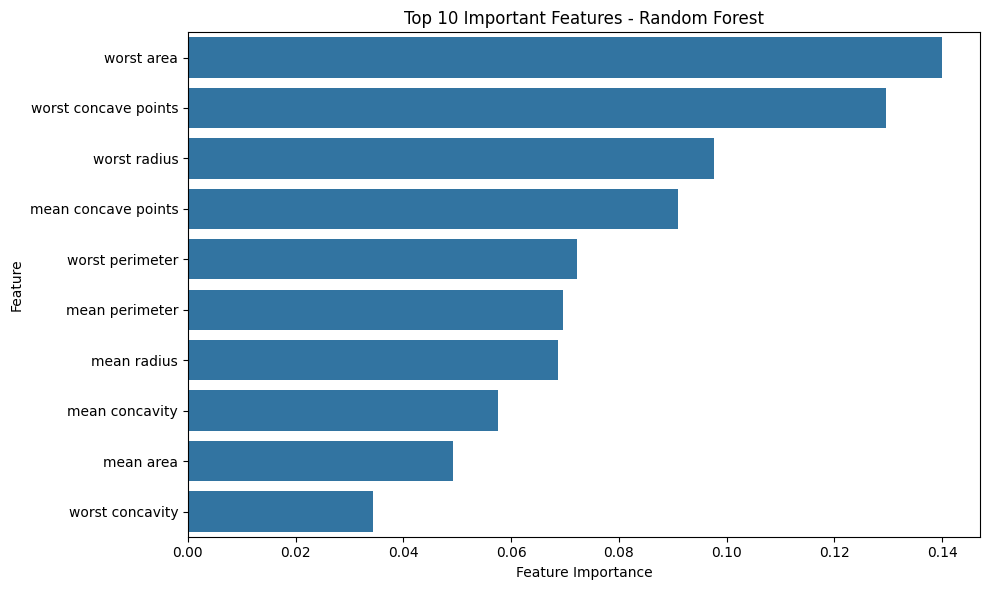

In [18]:

# Extract feature importance from Random Forest
rf_model = final_models['Random Forest']

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.named_steps['model'].feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10 features
display(feature_importance.head(10).round(4))

# Plot top 10 features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()
